In [ ]:
!pip install -q roboflow

In [ ]:
from roboflow import Roboflow
from getpass import getpass

api_key = getpass("T1kWUvfSQp8u4BquZIYm")

rf = Roboflow(api_key=api_key)

project = rf.workspace("dog-eyes").project("dog-eyes_ver.4")

dataset = project.version(1).download("yolov8")

print("Dataset downloaded at:", dataset.location)

T1kWUvfSQp8u4BquZIYm··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to DOG-EYES_ver.4-1 in yolov8:: 100%|██████████| 27806/27806 [00:03<00:00, 8118.94it/s] 


Dataset downloaded at: /content/DOG-EYES_ver.4-1


In [ ]:
import os

print(os.listdir(dataset.location))

['test', 'README.roboflow.txt', 'train', 'data.yaml', 'valid', 'README.dataset.txt']


In [ ]:
import os, yaml, glob
from collections import Counter

DATA_DIR = dataset.location
print("Root contents:", os.listdir(DATA_DIR))

# 1) data.yaml -> class names
with open(f"{DATA_DIR}/data.yaml") as f:
    cfg = yaml.safe_load(f)
print("\ndata.yaml:", cfg)

# 2) Folder structure + file counts
for split in ["train", "valid", "test"]:
    p = f"{DATA_DIR}/{split}"
    if os.path.isdir(p):
        print(f"\n[{split}] subfolders: {os.listdir(p)}")
        imgs = glob.glob(f"{p}/images/*")
        lbls = glob.glob(f"{p}/labels/*.txt")
        print(f"   images: {len(imgs)} | label files: {len(lbls)}")

# 3) Boxes per class + boxes per image
names = cfg.get("names", [])
for split in ["train", "valid", "test"]:
    cnt, per_img = Counter(), []
    for lf in glob.glob(f"{DATA_DIR}/{split}/labels/*.txt"):
        lines = [l.split() for l in open(lf).read().strip().splitlines() if l.strip()]
        per_img.append(len(lines))
        for l in lines:
            cnt[int(l[0])] += 1
    print(f"\n[{split}] boxes per class:")
    for k in sorted(cnt):
        nm = names[k] if isinstance(names, list) and k < len(names) else k
        print(f"   {k} ({nm}): {cnt[k]}")
    if per_img:
        print(f"   boxes per image -> min {min(per_img)}, max {max(per_img)}, "
              f"avg {sum(per_img)/len(per_img):.2f}, images with 0 boxes: {per_img.count(0)}")

# 4) Show 2 sample label lines
sample = glob.glob(f"{DATA_DIR}/train/labels/*.txt")[:2]
for s in sample:
    print("\n", os.path.basename(s), "->", open(s).read().strip()[:200])

Root contents: ['test', 'README.roboflow.txt', 'train', 'data.yaml', 'valid', 'README.dataset.txt']

data.yaml: {'names': ['Pigmented keratitis', 'blepharitis', 'entropion', 'eyelid_tumor', 'mastopathy'], 'nc': 5, 'roboflow': {'license': 'CC BY 4.0', 'project': 'dog-eyes_ver.4', 'url': 'https://universe.roboflow.com/dog-eyes/dog-eyes_ver.4/dataset/1', 'version': 1, 'workspace': 'dog-eyes'}, 'test': '../test/images', 'train': '../train/images', 'val': '../valid/images'}

[train] subfolders: ['labels', 'images']
   images: 12447 | label files: 12447

[valid] subfolders: ['labels', 'images']
   images: 888 | label files: 888

[test] subfolders: ['labels', 'images']
   images: 562 | label files: 562

[train] boxes per class:
   0 (Pigmented keratitis): 1680
   1 (blepharitis): 1470
   2 (entropion): 1470
   3 (eyelid_tumor): 1470
   4 (mastopathy): 1470
   boxes per image -> min 0, max 1, avg 0.61, images with 0 boxes: 4887

[valid] boxes per class:
   0 (Pigmented keratitis): 70
   1 (ble

[train] boxes: 7560 | full-image boxes (w,h>0.95): 34.7% | median w=0.95, h=0.93
[valid] boxes: 629 | full-image boxes (w,h>0.95): 16.2% | median w=0.84, h=0.78
[test] boxes: 351 | full-image boxes (w,h>0.95): 13.7% | median w=0.84, h=0.80

Unique original images in train: 4050 (from 12447 files)
Originals with mixed labels (some copies empty, some labelled): 0


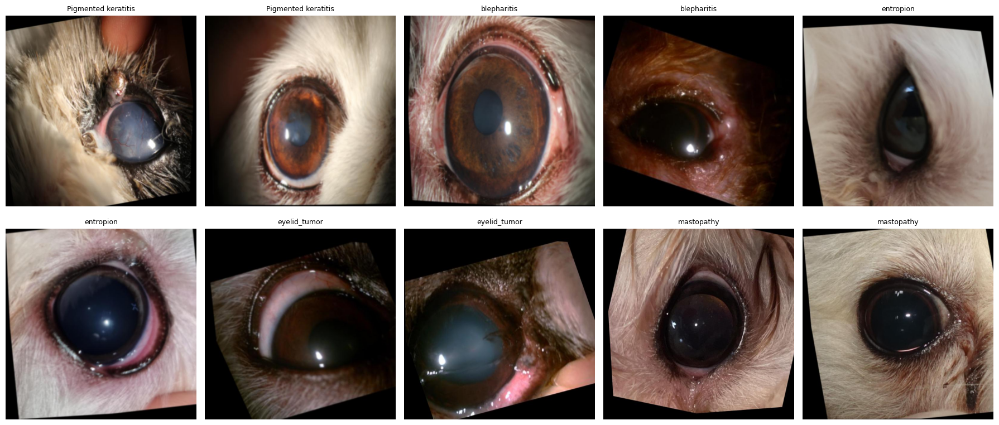

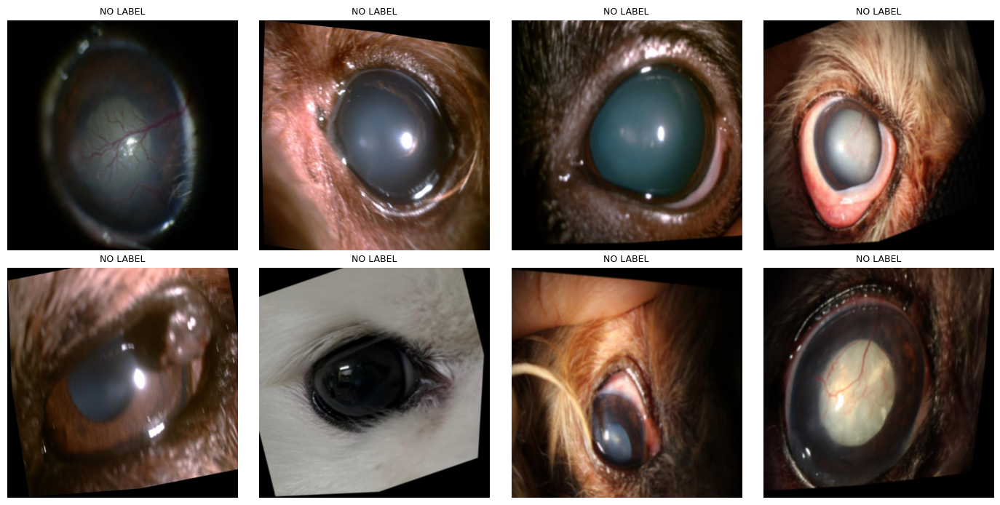

In [ ]:
import glob, os, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

names = cfg["names"]

# 1) Are boxes full-image or small? (w, h are fractions of the image)
for split in ["train", "valid", "test"]:
    ws, hs = [], []
    for lf in glob.glob(f"{DATA_DIR}/{split}/labels/*.txt"):
        for l in open(lf).read().strip().splitlines():
            p = l.split()
            if len(p) >= 5:
                ws.append(float(p[3])); hs.append(float(p[4]))
    ws, hs = np.array(ws), np.array(hs)
    full = ((ws > 0.95) & (hs > 0.95)).mean()
    print(f"[{split}] boxes: {len(ws)} | full-image boxes (w,h>0.95): {full:.1%} | "
          f"median w={np.median(ws):.2f}, h={np.median(hs):.2f}")

# 2) Do the same original photos appear with different labels / empty labels?
def group_key(fname): return fname.split(".rf.")[0]
train_lbls = glob.glob(f"{DATA_DIR}/train/labels/*.txt")
by_orig = {}
for lf in train_lbls:
    txt = open(lf).read().strip()
    cls = txt.split()[0] if txt else "none"
    by_orig.setdefault(group_key(os.path.basename(lf)), set()).add(cls)
print(f"\nUnique original images in train: {len(by_orig)} (from {len(train_lbls)} files)")
print("Originals with mixed labels (some copies empty, some labelled):",
      sum(1 for s in by_orig.values() if len(s) > 1))

# 3) Visual check: 1 labelled image per class + 8 images with NO box
def show(paths, titles, rows, cols, size=(14, 7)):
    fig, axes = plt.subplots(rows, cols, figsize=size)
    for ax, p, t in zip(np.array(axes).flat, paths, titles):
        ax.imshow(Image.open(p)); ax.set_title(t, fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

random.seed(0)
paths, titles = [], []
for k, nm in enumerate(names):
    cands = [lf for lf in train_lbls if open(lf).read().strip().startswith(str(k))]
    for lf in random.sample(cands, 2):
        img = lf.replace("/labels/", "/images/").rsplit(".", 1)[0] + ".jpg"
        paths.append(img); titles.append(nm)
show(paths, titles, 2, 5, (18, 8))

empty = [lf for lf in train_lbls if not open(lf).read().strip()]
epaths = [lf.replace("/labels/", "/images/").rsplit(".", 1)[0] + ".jpg" for lf in random.sample(empty, 8)]
epaths = [p for p in epaths if os.path.exists(p)]
show(epaths, ["NO LABEL"] * len(epaths), 2, 4)

# DOG-EYES_ver.4 > 2023-01-31 4:15pm
https://universe.roboflow.com/dog-eyes/dog-eyes_ver.4

Provided by a Roboflow user
License: CC BY 4.0


------------------------------------------------------------
Leaky files removed -> valid: 51, test: 28

Files per class (labelled only):
[train] {'blepharitis': 1470, 'entropion': 1470, 'eyelid_tumor': 1470, 'mastopathy': 1470, 'pigmented_keratitis': 1680} | total 7560
[valid] {'blepharitis': 140, 'entropion': 140, 'eyelid_tumor': 139, 'mastopathy': 122, 'pigmented_keratitis': 70} | total 611
[test] {'blepharitis': 70, 'entropion': 70, 'eyelid_tumor': 71, 'mastopathy': 60, 'pigmented_keratitis': 70} | total 341

Unique original photos per class in train: {'blepharitis': 490, 'entropion': 490, 'eyelid_tumor': 489, 'mastopathy': 458, 'pigmented_keratitis': 560}
Unlabelled images: Counter({'train': 4887, 'valid': 226, 'test': 193})


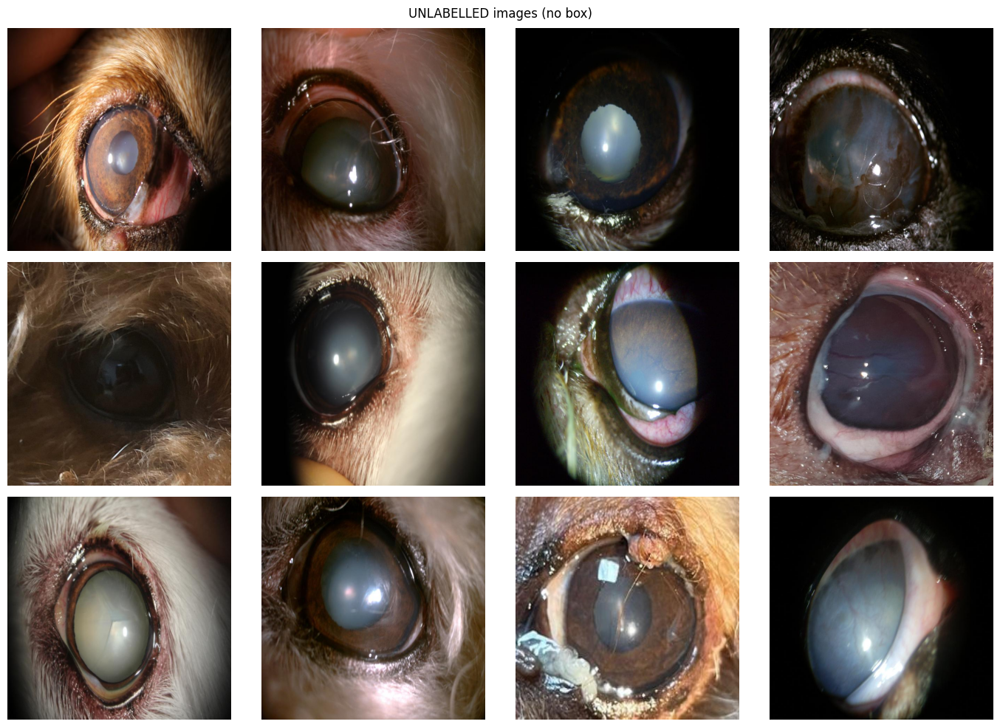

In [ ]:
import os, glob, shutil, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from collections import Counter

# Dataset notes (license, description)
print(open(f"{DATA_DIR}/README.dataset.txt").read()[:1500])
print("-" * 60)

names = cfg["names"]
safe = [n.strip().lower().replace(" ", "_") for n in names]
OUT = "/content/eye_cls"
shutil.rmtree(OUT, ignore_errors=True)

def key_of(stem): return stem.split(".rf.")[0]

records = {s: [] for s in ["train", "valid", "test"]}   # (img_path, class_idx or None, original_key)
for split in records:
    for lf in glob.glob(f"{DATA_DIR}/{split}/labels/*.txt"):
        stem = os.path.splitext(os.path.basename(lf))[0]
        hits = glob.glob(f"{DATA_DIR}/{split}/images/{stem}.*")
        if not hits:
            continue
        lines = [l.split() for l in open(lf).read().strip().splitlines() if l.strip()]
        records[split].append((hits[0], int(lines[0][0]) if lines else None, key_of(stem)))

# Leakage: same original photo in more than one split -> remove it from valid/test
train_keys = {k for _, _, k in records["train"]}
valid_keys = {k for _, _, k in records["valid"]}
leak_v = [r for r in records["valid"] if r[2] in train_keys]
leak_t = [r for r in records["test"] if r[2] in train_keys or r[2] in valid_keys]
print(f"Leaky files removed -> valid: {len(leak_v)}, test: {len(leak_t)}")
records["valid"] = [r for r in records["valid"] if r[2] not in train_keys]
records["test"]  = [r for r in records["test"]  if r[2] not in train_keys and r[2] not in valid_keys]

# Symlink labelled images into class folders (ImageFolder layout)
unlabeled = []
for split, recs in records.items():
    for img, cls, key in recs:
        if cls is None:
            unlabeled.append((split, img)); continue
        d = f"{OUT}/{split}/{safe[cls]}"
        os.makedirs(d, exist_ok=True)
        os.symlink(os.path.abspath(img), f"{d}/{os.path.basename(img)}")

print("\nFiles per class (labelled only):")
for split in ["train", "valid", "test"]:
    c = Counter(safe[cls] for _, cls, _ in records[split] if cls is not None)
    print(f"[{split}]", dict(sorted(c.items())), "| total", sum(c.values()))

uniq = {}
for _, cls, key in records["train"]:
    if cls is not None:
        uniq.setdefault(safe[cls], set()).add(key)
print("\nUnique original photos per class in train:", {k: len(v) for k, v in sorted(uniq.items())})
print("Unlabelled images:", Counter(s for s, _ in unlabeled))

# View 12 UNLABELLED images from valid/test (raw photos, not augmented)
raw_unl = [p for s, p in unlabeled if s in ("valid", "test")]
random.seed(1)
sel = random.sample(raw_unl, min(12, len(raw_unl)))
fig, axes = plt.subplots(3, 4, figsize=(14, 10))
for ax, p in zip(axes.flat, sel):
    ax.imshow(Image.open(p)); ax.axis("off")
plt.suptitle("UNLABELLED images (no box)"); plt.tight_layout(); plt.show()

In [ ]:
import torch, torch.nn as nn, numpy as np, time
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
from torch.amp import autocast, GradScaler

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
assert device.type == "cuda", "Switch runtime to GPU first (Runtime > Change runtime type > T4 GPU)"
print("GPU:", torch.cuda.get_device_name(0))

EYE_DIR = "/content/eye_cls"
IMG_SIZE, BATCH_SIZE = 224, 32
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15),   # no hue shift
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
eval_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])

train_ds = datasets.ImageFolder(f"{EYE_DIR}/train", transform=train_tfms)
val_ds   = datasets.ImageFolder(f"{EYE_DIR}/valid", transform=eval_tfms)
test_ds  = datasets.ImageFolder(f"{EYE_DIR}/test",  transform=eval_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)

class_names = train_ds.classes
NUM_CLASSES = len(class_names)
print("Classes:", train_ds.class_to_idx)
print(f"Train {len(train_ds)} | Val {len(val_ds)} | Test {len(test_ds)}")

counts = np.bincount(train_ds.targets)
class_weights = torch.tensor(counts.sum() / (NUM_CLASSES * counts), dtype=torch.float).to(device)
print("Class weights:", class_weights.cpu().numpy().round(3))

# --- Model: EfficientNet-B0, new 5-class head ---
model = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
model.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(model.classifier[1].in_features, NUM_CLASSES))
model = model.to(device)
for p in model.features.parameters():
    p.requires_grad = False          # stage 1: train the head only

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
scaler = GradScaler("cuda")

def run_epoch(loader, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total_loss = correct = n = 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with autocast("cuda"):
                out = model(x)
                loss = criterion(out, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

# --- Stage 1 ---
EPOCHS_1 = 4
optimizer = torch.optim.AdamW(model.classifier.parameters(), lr=1e-3, weight_decay=1e-4)
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val = 0.0
for epoch in range(1, EPOCHS_1 + 1):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, optimizer)
    vl, va = run_epoch(val_loader)
    for k, v in zip(history, (tl, ta, vl, va)):
        history[k].append(v)
    if va > best_val:
        best_val = va
        torch.save(model.state_dict(), "best_eye_model.pth")
    print(f"[Stage 1] Epoch {epoch}/{EPOCHS_1} | train loss {tl:.4f} acc {ta:.4f} | "
          f"val loss {vl:.4f} acc {va:.4f} | {time.time()-t0:.0f}s")
print("Best val acc:", round(best_val, 4))

GPU: Tesla T4
Classes: {'blepharitis': 0, 'entropion': 1, 'eyelid_tumor': 2, 'mastopathy': 3, 'pigmented_keratitis': 4}
Train 7560 | Val 611 | Test 341
Class weights: [1.029 1.029 1.029 1.029 0.9  ]
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 164MB/s]


[Stage 1] Epoch 1/4 | train loss 1.1597 acc 0.5873 | val loss 1.0691 acc 0.6268 | 75s
[Stage 1] Epoch 2/4 | train loss 1.0094 acc 0.6771 | val loss 1.0313 acc 0.6432 | 71s
[Stage 1] Epoch 3/4 | train loss 0.9852 acc 0.6816 | val loss 0.9921 acc 0.6678 | 70s
[Stage 1] Epoch 4/4 | train loss 0.9620 acc 0.7052 | val loss 0.9863 acc 0.6776 | 69s
Best val acc: 0.6776


[Stage 2] Epoch 1/14 | train loss 0.8252 acc 0.7796 | val loss 0.7973 acc 0.7758 | 88s  <- saved
[Stage 2] Epoch 2/14 | train loss 0.6662 acc 0.8758 | val loss 0.7916 acc 0.7971 | 83s  <- saved
[Stage 2] Epoch 3/14 | train loss 0.6177 acc 0.9041 | val loss 0.7676 acc 0.8134 | 79s  <- saved
[Stage 2] Epoch 4/14 | train loss 0.5742 acc 0.9237 | val loss 0.7765 acc 0.8134 | 81s
[Stage 2] Epoch 5/14 | train loss 0.5543 acc 0.9366 | val loss 0.7927 acc 0.8167 | 80s  <- saved
[Stage 2] Epoch 6/14 | train loss 0.5391 acc 0.9393 | val loss 0.7891 acc 0.8298 | 79s  <- saved
[Stage 2] Epoch 7/14 | train loss 0.5265 acc 0.9446 | val loss 0.7646 acc 0.8134 | 80s
[Stage 2] Epoch 8/14 | train loss 0.5157 acc 0.9520 | val loss 0.7827 acc 0.8134 | 80s
[Stage 2] Epoch 9/14 | train loss 0.5105 acc 0.9546 | val loss 0.7764 acc 0.8151 | 80s
[Stage 2] Epoch 10/14 | train loss 0.5048 acc 0.9570 | val loss 0.7737 acc 0.8118 | 78s
[Stage 2] Epoch 11/14 | train loss 0.4973 acc 0.9585 | val loss 0.7854 acc 0.81

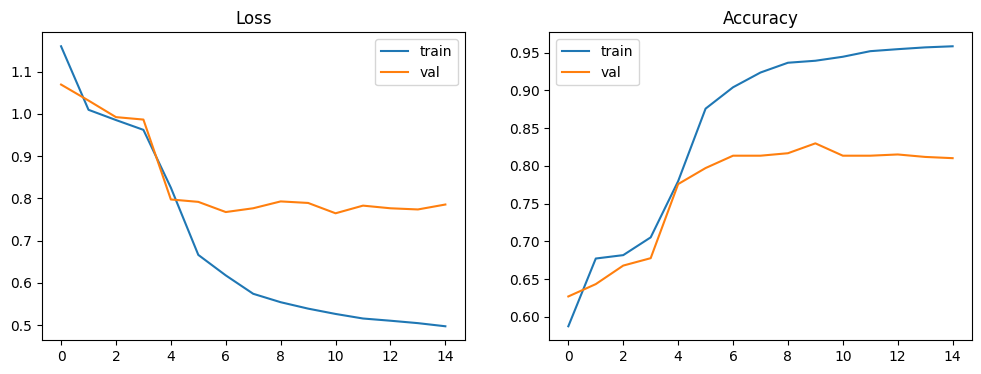

In [ ]:
import matplotlib.pyplot as plt

for p in model.parameters():
    p.requires_grad = True

EPOCHS_2 = 14
PATIENCE = 5

optimizer = torch.optim.AdamW([
    {"params": model.features.parameters(),   "lr": 1e-4},
    {"params": model.classifier.parameters(), "lr": 5e-4},
], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS_2, eta_min=1e-6)

no_improve = 0
for epoch in range(1, EPOCHS_2 + 1):
    t0 = time.time()
    tl, ta = run_epoch(train_loader, optimizer)
    vl, va = run_epoch(val_loader)
    scheduler.step()
    for k, v in zip(history, (tl, ta, vl, va)):
        history[k].append(v)

    flag = ""
    if va > best_val:
        best_val, no_improve = va, 0
        torch.save(model.state_dict(), "best_eye_model.pth")
        flag = "  <- saved"
    else:
        no_improve += 1

    print(f"[Stage 2] Epoch {epoch}/{EPOCHS_2} | train loss {tl:.4f} acc {ta:.4f} | "
          f"val loss {vl:.4f} acc {va:.4f} | {time.time()-t0:.0f}s{flag}")
    if no_improve >= PATIENCE:
        print(f"Early stopping: no val improvement for {PATIENCE} epochs.")
        break

print("Best val acc:", round(best_val, 4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["train_loss"], label="train"); ax[0].plot(history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history["train_acc"], label="train"); ax[1].plot(history["val_acc"], label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()


Test accuracy: 0.8387

                     precision    recall  f1-score   support

        blepharitis      0.843     0.843     0.843        70
          entropion      0.865     0.643     0.738        70
       eyelid_tumor      0.900     0.887     0.894        71
         mastopathy      0.688     0.917     0.786        60
pigmented_keratitis      0.928     0.914     0.921        70

           accuracy                          0.839       341
          macro avg      0.845     0.841     0.836       341
       weighted avg      0.849     0.839     0.838       341



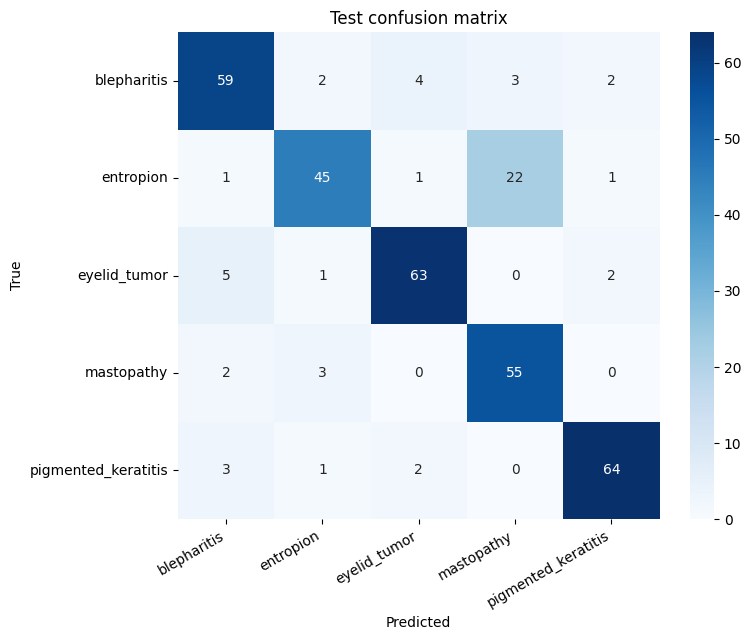

Mean confidence | correct: 0.86 | wrong: 0.70


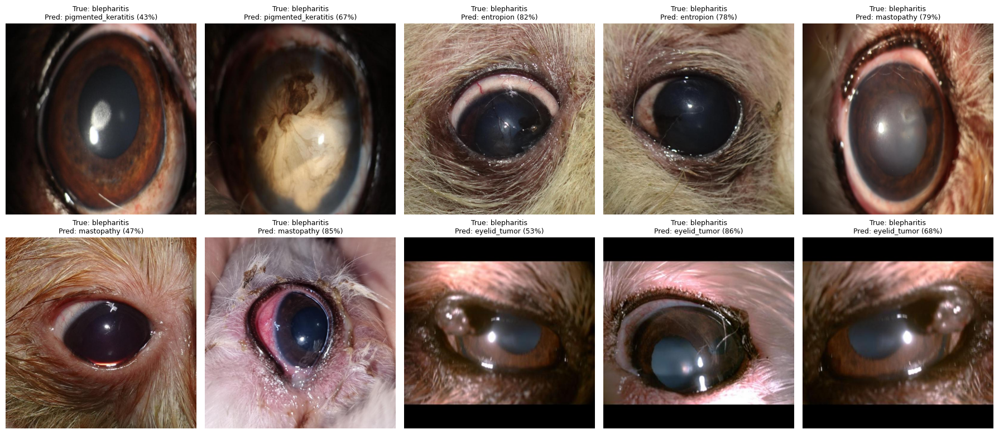

In [ ]:
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

model.load_state_dict(torch.load("best_eye_model.pth", map_location=device))
model.eval()

all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for x, y in test_loader:
        with autocast("cuda"):
            out = model(x.to(device))
        probs = torch.softmax(out.float(), dim=1).cpu()
        all_probs.append(probs)
        all_preds.extend(probs.argmax(1).tolist())
        all_labels.extend(y.tolist())

all_preds, all_labels = np.array(all_preds), np.array(all_labels)
print(f"Test accuracy: {(all_preds == all_labels).mean():.4f}\n")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=3))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Test confusion matrix")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

# Confidence of correct vs wrong predictions
probs_all = torch.cat(all_probs).numpy()
conf = probs_all.max(1)
print(f"Mean confidence | correct: {conf[all_preds == all_labels].mean():.2f} | "
      f"wrong: {conf[all_preds != all_labels].mean():.2f}")

# Show 10 misclassified test images
from PIL import Image
wrong = np.where(all_preds != all_labels)[0][:10]
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax, i in zip(axes.flat, wrong):
    path, _ = test_ds.samples[i]
    ax.imshow(Image.open(path))
    ax.set_title(f"True: {class_names[all_labels[i]]}\nPred: {class_names[all_preds[i]]} ({conf[i]:.0%})", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

Most common mistakes (true -> predicted):
  entropion            -> mastopathy           22
  eyelid_tumor         -> blepharitis          5
  blepharitis          -> eyelid_tumor         4
  blepharitis          -> mastopathy           3
  mastopathy           -> entropion            3
  pigmented_keratitis  -> blepharitis          3
  blepharitis          -> pigmented_keratitis  2
  blepharitis          -> entropion            2

Threshold | answered | accuracy on answered
  >= 0.0: 100.0% | 0.839
  >= 0.5:  95.0% | 0.861
  >= 0.6:  87.7% | 0.876
  >= 0.7:  82.1% | 0.896
  >= 0.8:  68.9% | 0.928
  >= 0.9:  46.6% | 0.969


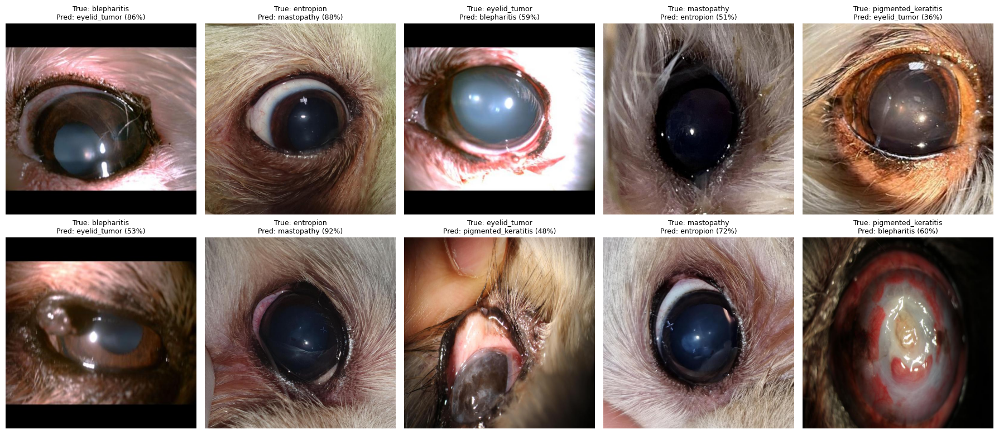

In [ ]:
from collections import Counter
from PIL import Image

# 1) Most common mistakes (true -> predicted)
pairs = Counter((class_names[l], class_names[p]) for l, p in zip(all_labels, all_preds) if l != p)
print("Most common mistakes (true -> predicted):")
for (t, p), n in pairs.most_common(8):
    print(f"  {t:20s} -> {p:20s} {n}")

# 2) Accuracy if the model only answers when confident
print("\nThreshold | answered | accuracy on answered")
for th in [0.0, 0.5, 0.6, 0.7, 0.8, 0.9]:
    m = conf >= th
    print(f"  >= {th:.1f}: {m.mean():6.1%} | {(all_preds[m] == all_labels[m]).mean():.3f}")

# 3) Two errors per TRUE class (balanced view)
rng = np.random.default_rng(0)
fig, axes = plt.subplots(2, 5, figsize=(18, 8))
for ax in axes.flat: ax.axis("off")
for c, name in enumerate(class_names):
    idx = np.where((all_labels == c) & (all_preds != c))[0]
    pick = rng.choice(idx, size=min(2, len(idx)), replace=False)
    for r, i in enumerate(pick):
        ax = axes[r, c]
        ax.imshow(Image.open(test_ds.samples[i][0]))
        ax.set_title(f"True: {name}\nPred: {class_names[all_preds[i]]} ({conf[i]:.0%})", fontsize=9)
        ax.axis("off")
plt.tight_layout(); plt.show()

Classes: ['blepharitis', 'entropion', 'eyelid_tumor', 'mastopathy', 'pigmented_keratitis']
Validation confusion matrix (rows = true, cols = predicted):
[[125   2   5   6   2]
 [  7  89   2  39   3]
 [  8   0 127   1   3]
 [  5  14   0 102   1]
 [  3   2   1   0  64]]
Val accuracy: 0.8298

Test confusion matrix (rows = true, cols = predicted):
[[59  2  4  3  2]
 [ 1 45  1 22  1]
 [ 5  1 63  0  2]
 [ 2  3  0 55  0]
 [ 3  1  2  0 64]]


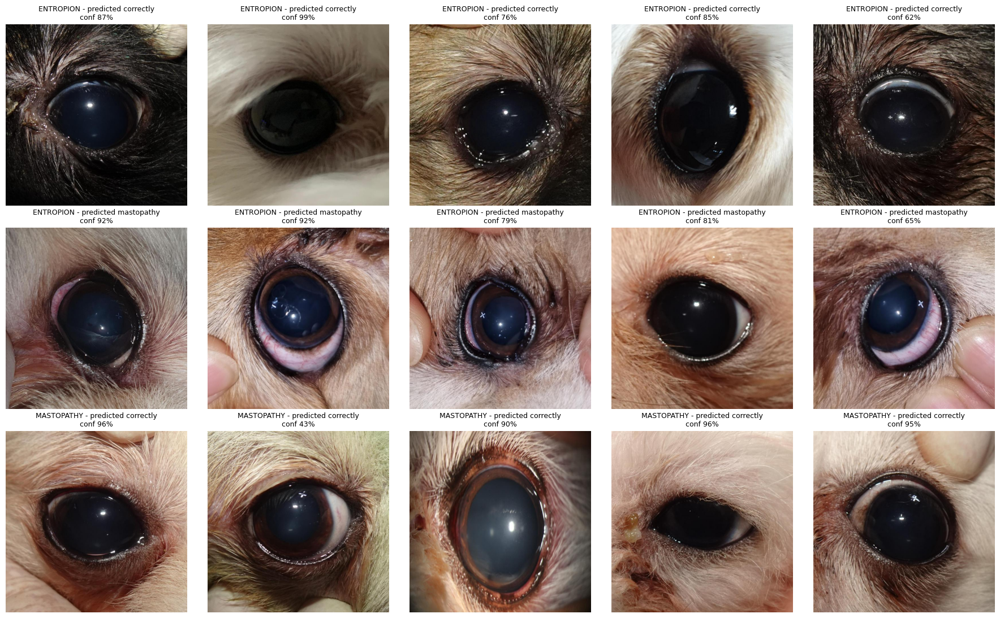

In [ ]:
from sklearn.metrics import confusion_matrix
from PIL import Image

# 1) Validation confusion matrix: is entropion -> mastopathy also a problem on valid?
def predict_loader(loader):
    P, L = [], []
    model.eval()
    with torch.no_grad():
        for x, y in loader:
            with autocast("cuda"):
                out = model(x.to(device))
            P.extend(out.float().argmax(1).cpu().tolist()); L.extend(y.tolist())
    return np.array(P), np.array(L)

vp, vl = predict_loader(val_loader)
print("Classes:", class_names)
print("Validation confusion matrix (rows = true, cols = predicted):")
print(confusion_matrix(vl, vp))
print(f"Val accuracy: {(vp == vl).mean():.4f}\n")

print("Test confusion matrix (rows = true, cols = predicted):")
print(confusion_matrix(all_labels, all_preds))

# 2) Look at them side by side (test set)
ent, mas = class_names.index("entropion"), class_names.index("mastopathy")
rows = [
    ("ENTROPION - predicted correctly",  np.where((all_labels == ent) & (all_preds == ent))[0]),
    ("ENTROPION - predicted mastopathy", np.where((all_labels == ent) & (all_preds == mas))[0]),
    ("MASTOPATHY - predicted correctly", np.where((all_labels == mas) & (all_preds == mas))[0]),
]
rng = np.random.default_rng(1)
fig, axes = plt.subplots(3, 5, figsize=(18, 11))
for r, (title, idx) in enumerate(rows):
    pick = rng.choice(idx, size=min(5, len(idx)), replace=False)
    for c in range(5):
        ax = axes[r, c]; ax.axis("off")
        if c < len(pick):
            ax.imshow(Image.open(test_ds.samples[pick[c]][0]))
            ax.set_title(f"{title}\nconf {conf[pick[c]]:.0%}", fontsize=9)
plt.tight_layout(); plt.show()

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import shutil; shutil.copy("best_eye_model.pth", "/content/drive/MyDrive/best_eye_model_v1.pth")

In [ ]:
import json, glob, random
from PIL import Image
from torchvision import models, transforms
import torch, torch.nn as nn
from torch.amp import autocast
from google.colab import files

CLASSES = ['blepharitis', 'entropion', 'eyelid_tumor', 'mastopathy', 'pigmented_keratitis']
SIZE, MEAN, STD = 224, [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

m = models.efficientnet_b0(weights=None)
m.classifier = nn.Sequential(nn.Dropout(0.3), nn.Linear(1280, len(CLASSES)))
m.load_state_dict(torch.load("best_eye_model.pth", map_location="cpu"))
m = m.to(device).eval()

torch.save({"model_state": m.state_dict(), "class_names": CLASSES, "img_size": SIZE,
            "mean": MEAN, "std": STD, "arch": "efficientnet_b0", "test_acc": 0.8387},
           "dog_eye_efficientnet_b0_v1.pth")
json.dump(CLASSES, open("eye_class_names.json", "w"))

tf = transforms.Compose([transforms.Resize((SIZE, SIZE)), transforms.ToTensor(),
                         transforms.Normalize(MEAN, STD)])

def predict_eye(path, threshold=0.70):
    x = tf(Image.open(path).convert("RGB")).unsqueeze(0).to(device)
    with torch.no_grad(), autocast("cuda"):
        probs = torch.softmax(m(x).float(), dim=1)[0].cpu().numpy()
    top = int(probs.argmax())
    return {"prediction": CLASSES[top], "confidence": float(probs[top]),
            "uncertain": bool(probs[top] < threshold),
            "all_probs": {c: round(float(p), 3) for c, p in zip(CLASSES, probs)}}

# Quick test on 4 random test images
random.seed(3)
for p in random.sample(glob.glob("/content/eye_cls/test/*/*"), 4):
    r = predict_eye(p)
    print(f"True: {p.split('/')[-2]:20s} -> {r['prediction']} ({r['confidence']:.0%})"
          f"{'  [UNCERTAIN]' if r['uncertain'] else ''}")

files.download("dog_eye_efficientnet_b0_v1.pth")
files.download("eye_class_names.json")

In [ ]:
|